# Module 4: Self-attention step by step
Companion to `docs/04_self_attention.html`. We build attention up from a plain average, check each step against PyTorch,
reproduce GPT-2's attention from its raw weight matrices, look at what real heads do, and train tiny attention models on Shakespeare.
Runs on a laptop CPU in about 8 minutes (the training cell in section 7 is the slow part; the GPT-2 download is the only network step besides the text file).

In [1]:
import os, math, time, urllib.request
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)

## 0. Attention code
One block, pasted from `tools/module04/attn_core.py` so this notebook is standalone: `attention` (a single head, any batch shape), `MultiHeadAttention`, and a small character language model built from it. Section 1 and 2 re-derive `attention` piece by piece.

In [2]:
# --- shared by data.py, figs.py and the notebook (mknb.py pastes this file into the notebook) ---
import math, torch, torch.nn as nn, torch.nn.functional as F

def attention(q, k, v, causal=True, scale=True):
    """Scaled dot-product attention. q, k, v: (..., T, d). Returns (output, weights)."""
    s = q @ k.transpose(-2, -1)                                   # (..., T, T): score[i, j] = q_i . k_j
    if scale: s = s / math.sqrt(q.shape[-1])
    if causal:
        T = s.shape[-1]
        s = s.masked_fill(torch.triu(torch.ones(T, T, dtype=torch.bool), 1), float("-inf"))   # hide the future
    w = F.softmax(s, dim=-1)                                      # each row sums to 1
    return w @ v, w

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dk = n_heads, d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)               # W_q, W_k, W_v side by side
        self.proj = nn.Linear(d_model, d_model)                   # W_o
    def forward(self, x, return_weights=False):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=-1)
        q, k, v = (z.view(B, T, self.h, self.dk).transpose(1, 2) for z in (q, k, v))      # (B, h, T, dk)
        y, w = attention(q, k, v)
        y = self.proj(y.transpose(1, 2).reshape(B, T, D))         # concatenate heads, mix with W_o
        return (y, w) if return_weights else y

class AttnLM(nn.Module):
    """Character LM: token + learned position embeddings, L attention layers with residuals, no MLP, no norm."""
    def __init__(self, V, T, d=64, h=4, L=1):
        super().__init__()
        self.T = T
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(T, d)
        self.att = nn.ModuleList(MultiHeadAttention(d, h) for _ in range(L))
        self.out = nn.Linear(d, V)
    def forward(self, x, return_weights=False):
        z = self.tok(x) + self.pos(torch.arange(x.shape[1]))
        ws = []
        for a in self.att:
            y, w = a(z, True); z = z + y; ws.append(w)
        logits = self.out(z)
        return (logits, ws) if return_weights else logits

def batches(ids, T, bs, g):
    ids = torch.as_tensor(ids, dtype=torch.long)
    i = torch.randint(0, len(ids) - T - 1, (bs,), generator=g)
    idx = i[:, None] + torch.arange(T + 1)[None, :]
    return ids[idx][:, :-1], ids[idx][:, 1:]

def train_attn(model, ids, steps=3000, bs=64, lr=3e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for s in range(steps):
        x, y = batches(ids, model.T, bs, g)
        loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model

@torch.no_grad()
def eval_attn(model, ids, min_pos=8):
    """Mean loss over non-overlapping windows, scoring only positions >= min_pos (so every prediction sees at least min_pos characters)."""
    ids = torch.as_tensor(ids, dtype=torch.long); T = model.T; n = (len(ids) - 1) // T
    x = ids[: n * T].view(n, T); y = ids[1 : n * T + 1].view(n, T)
    tot = 0.0
    for i in range(0, n, 256):
        lg = model(x[i:i+256])[:, min_pos:]
        tot += float(F.cross_entropy(lg.flatten(0, 1), y[i:i+256, min_pos:].flatten(), reduction="sum"))
    return tot / (n * (T - min_pos))

@torch.no_grad()
def sample_attn(model, chars, stoi, prompt, n_new, seed=0):
    g = torch.Generator().manual_seed(seed); ids = [stoi[c] for c in prompt]
    for _ in range(n_new):
        ctx = torch.tensor([ids[-model.T:]])
        p = F.softmax(model(ctx)[0, -1], -1)
        ids.append(int(torch.multinomial(p, 1, generator=g)))
    return "".join(chars[i] for i in ids)

## 1. Averaging the past, three ways
The simplest "look at earlier tokens" is the mean of all vectors up to and including position `i`. We write it as a loop, as a matrix product with a lower-triangular matrix, and as a softmax over equal scores with a mask. All three are the same.

In [3]:
T, d = 6, 4
X = torch.randn(T, d)
loop = torch.stack([X[: i + 1].mean(0) for i in range(T)])

A = torch.tril(torch.ones(T, T)); A = A / A.sum(1, keepdim=True)         # row i: 1/(i+1) on the first i+1 entries
matmul = A @ X

scores = torch.zeros(T, T).masked_fill(torch.triu(torch.ones(T, T, dtype=torch.bool), 1), float("-inf"))
soft = F.softmax(scores, -1) @ X                                          # equal scores + causal mask = running mean
print(A)
print("loop == matmul:", torch.allclose(loop, matmul), "  matmul == softmax:", torch.allclose(matmul, soft))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667]])
loop == matmul: True   matmul == softmax: True


Attention keeps `out = A @ values` with `A` lower-triangular and rows summing to 1, but computes `scores` from the tokens instead of setting them to 0.

## 2. Queries, keys, values: the worked example of the lesson
Four tokens, `d_k = 2`. Check the numbers of Figure 2.

In [4]:
q = torch.tensor([[1., 0.], [0., 1.], [1., 1.], [2., -1.]])
k = torch.tensor([[1., 0.], [0., 2.], [1., 1.], [-1., 1.]])
v = torch.tensor([[1., 0.], [0., 1.], [2., 2.], [0., -2.]])
print("raw scores q.k^T:\n", q @ k.T)
out, w = attention(q, k, v)
print("weights (rows sum to 1, zeros above the diagonal):\n", w.round(decimals=2))
print("output = weights @ V:\n", out.round(decimals=2))
print("row sums:", w.sum(1))

raw scores q.k^T:
 tensor([[ 1.,  0.,  1., -1.],
        [ 0.,  2.,  1.,  1.],
        [ 1.,  2.,  2.,  0.],
        [ 2., -2.,  1., -3.]])
weights (rows sum to 1, zeros above the diagonal):
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.8000, 0.0000, 0.0000],
        [0.2000, 0.4000, 0.4000, 0.0000],
        [0.6300, 0.0400, 0.3100, 0.0200]])
output = weights @ V:
 tensor([[1.0000, 0.0000],
        [0.2000, 0.8000],
        [1.0000, 1.2000],
        [1.2600, 0.6200]])
row sums: tensor([1., 1., 1., 1.])


Compare with PyTorch's fused implementation, `F.scaled_dot_product_attention` (the function that the Hugging Face default "sdpa" path calls).

In [5]:
ref = F.scaled_dot_product_attention(q, k, v, is_causal=True)
print("matches PyTorch:", torch.allclose(out, ref, atol=1e-6))

# with a batch and several heads the same function works unchanged: shape (batch, heads, T, d_k)
qb, kb, vb = (torch.randn(3, 5, 10, 16) for _ in range(3))
ob, wb = attention(qb, kb, vb)
print("batched:", torch.allclose(ob, F.scaled_dot_product_attention(qb, kb, vb, is_causal=True), atol=1e-5), wb.shape)

matches PyTorch: True
batched: True torch.Size([3, 5, 10, 10])


## 3. Why divide by sqrt(d_k)
With unit-variance entries the dot product has variance `d_k`. Measure it, and see how peaked the softmax gets.

In [6]:
g = torch.Generator().manual_seed(0)
print(f"{'d_k':>5} {'std(q.k)':>9} {'std scaled':>11} {'max weight raw':>15} {'max weight scaled':>18}")
for dk in (4, 16, 64, 256, 1024):
    qq = torch.randn(4000, dk, generator=g); kk = torch.randn(4000, 32, dk, generator=g)
    s = torch.einsum("qd,qkd->qk", qq, kk)
    print(f"{dk:>5} {s.std():9.2f} {(s/math.sqrt(dk)).std():11.2f} {F.softmax(s,-1).max(-1).values.mean():15.3f} {F.softmax(s/math.sqrt(dk),-1).max(-1).values.mean():18.3f}")

  d_k  std(q.k)  std scaled  max weight raw  max weight scaled
    4      2.01        1.00           0.344              0.159
   16      3.99        1.00           0.628              0.161
   64      8.00        1.00           0.814              0.165


  256     15.98        1.00           0.906              0.163


 1024     31.92        1.00           0.952              0.162


The gradient problem: the softmax Jacobian is `diag(p) - p p^T`. When one weight is near 1 the whole Jacobian is near 0, so no gradient reaches the other scores (and so the other keys and the query). We print its largest entry at `d_k = 1024`, averaged over 200 random queries.

In [7]:
dk = 1024; g = torch.Generator().manual_seed(0); res = {"unscaled": [], "scaled": []}
for _ in range(200):
    qq = torch.randn(dk, generator=g); kk = torch.randn(32, dk, generator=g)
    for name, sc in (("unscaled", 1.0), ("scaled", 1 / math.sqrt(dk))):
        p = F.softmax(kk @ qq * sc, -1)
        res[name].append((torch.diag(p) - torch.outer(p, p)).abs().max().item())
for name, v in res.items(): print(f"{name:9s} largest Jacobian entry of the softmax: {np.mean(v):.4f}   (maximum possible is 0.25)")

unscaled  largest Jacobian entry of the softmax: 0.0360   (maximum possible is 0.25)
scaled    largest Jacobian entry of the softmax: 0.1372   (maximum possible is 0.25)


## 4. Multi-head attention
`MultiHeadAttention` (section 0) uses one fused `d x 3d` projection, splits the result into `h` heads with a reshape, runs `attention` on all heads at once, concatenates, and applies `W_o`. We verify against `nn.MultiheadAttention` by copying the weights across.

In [8]:
d, h, T = 32, 4, 10
mine = MultiHeadAttention(d, h)
ref = nn.MultiheadAttention(d, h, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(mine.qkv.weight); ref.in_proj_bias.copy_(mine.qkv.bias)
    ref.out_proj.weight.copy_(mine.proj.weight); ref.out_proj.bias.copy_(mine.proj.bias)
x = torch.randn(2, T, d)
y, w = mine(x, return_weights=True)
mask = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)
y2, w2 = ref(x, x, x, attn_mask=mask, need_weights=True, average_attn_weights=False)
print("outputs match:", torch.allclose(y, y2, atol=1e-5), "  weights match:", torch.allclose(w, w2, atol=1e-6))

outputs match: True   weights match: True


Parameter count does not depend on the number of heads, but the score tables do grow with them (and with T squared).

In [9]:
for h in (1, 2, 4, 8, 16):
    print(f"d=64, heads={h:2d}: parameters {sum(p.numel() for p in MultiHeadAttention(64, h).parameters()):,}   score numbers per sequence at T=1024: {h*1024*1024:,}")
print("GPT-2 small, one attention layer: ", sum(p.numel() for p in MultiHeadAttention(768, 12).parameters()), "parameters")

d=64, heads= 1: parameters 16,640   score numbers per sequence at T=1024: 1,048,576
d=64, heads= 2: parameters 16,640   score numbers per sequence at T=1024: 2,097,152
d=64, heads= 4: parameters 16,640   score numbers per sequence at T=1024: 4,194,304
d=64, heads= 8: parameters 16,640   score numbers per sequence at T=1024: 8,388,608
d=64, heads=16: parameters 16,640   score numbers per sequence at T=1024: 16,777,216


GPT-2 small, one attention layer:  2362368 parameters


Without positional information attention is permutation-equivariant (no mask here, since the mask is what breaks the symmetry): permute the input and the output is permuted the same way.

In [10]:
mha = MultiHeadAttention(32, 4)
def free_attn(x):                                                 # same as mha but without the causal mask
    B, T, D = x.shape
    q, k, v = mha.qkv(x).split(D, -1)
    q, k, v = (z.view(B, T, 4, 8).transpose(1, 2) for z in (q, k, v))
    y, _ = attention(q, k, v, causal=False)
    return mha.proj(y.transpose(1, 2).reshape(B, T, D))
x = torch.randn(1, 7, 32); perm = torch.randperm(7)
print("permutation equivariant:", torch.allclose(free_attn(x)[:, perm], free_attn(x[:, perm]), atol=1e-5))

permutation equivariant: True


## 5. GPT-2's attention from its raw weights
Load GPT-2 small (`attn_implementation="eager"` so that the Hugging Face model returns attention weights). We take layer 5, build q, k, v from its `c_attn` weights with our own `attention`, and compare the weights and the whole block output with the model's.

In [11]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
tok = GPT2TokenizerFast.from_pretrained("gpt2")
gm = GPT2LMHeadModel.from_pretrained("gpt2", attn_implementation="eager").eval()
text = open(path).read() if os.path.exists(path := "data/tinyshakespeare.txt") else None
if text is None:
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", path)
    text = open(path).read()
enc = tok.encode(text[:200000]); T = 128
chunks = torch.tensor([enc[i * T:(i + 1) * T] for i in range(12)])
with torch.no_grad():
    o = gm(chunks, output_attentions=True, output_hidden_states=True)
A = torch.stack(o.attentions)                                     # (layers, windows, heads, T, T)
print("attention tensor:", tuple(A.shape))

/home/ayush/llm_learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 5135.95it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (60826 > 1024). Running this sequence through the model will result in indexing errors


attention tensor: (12, 12, 12, 128, 128)


In [12]:
l = 5; blk = gm.transformer.h[l]
with torch.no_grad():
    x = blk.ln_1(o.hidden_states[l])                              # what the attention of layer l reads
    q_, k_, v_ = (x @ blk.attn.c_attn.weight + blk.attn.c_attn.bias).split(768, -1)   # GPT-2's Conv1D stores weight as (in, out)
    sp = lambda z: z.view(12, T, 12, 64).transpose(1, 2)          # 12 heads of 64 dims
    y, w_ = attention(sp(q_), sp(k_), sp(v_))
    att_out = y.transpose(1, 2).reshape(12, T, 768) @ blk.attn.c_proj.weight + blk.attn.c_proj.bias
    h1 = o.hidden_states[l] + att_out                             # residual connection (Module 5)
    h2 = h1 + blk.mlp(blk.ln_2(h1))                               # the block's other half
print("max |our weights - Hugging Face weights|:", (w_ - A[l]).abs().max().item())
print("max |our block output - Hugging Face block output|:", (h2 - o.hidden_states[l + 1]).abs().max().item())

max |our weights - Hugging Face weights|: 5.960464477539062e-07
max |our block output - Hugging Face block output|: 2.288818359375e-05


## 6. What do the heads do?
Three statistics over all 144 heads:
- **previous-token score**: mean attention on the token just before the query;
- **first-token share** (attention sink): mean attention on position 0;
- **induction score** (Olsson et al. 2022): repeat a random token sequence twice, and measure, at positions in the second copy, the weight on the token *after* the earlier occurrence of the current token.

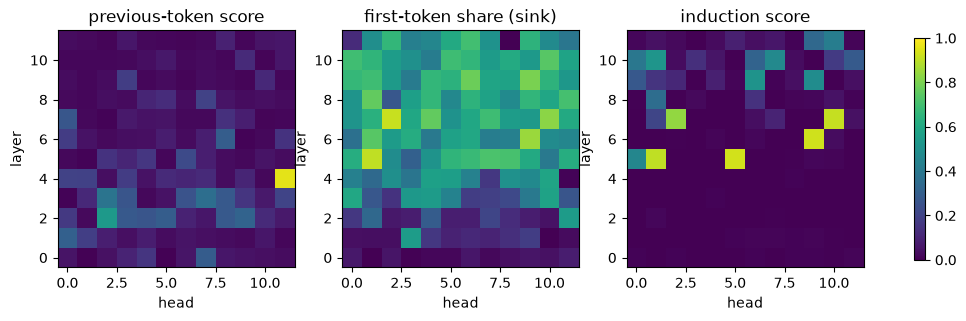

best previous-token head: layer 4, head 11, score 0.96
best induction head: layer 5, head 5, score 0.93
uniform attention would give the previous token on average: 0.035


In [13]:
idx = torch.arange(T)
prev = torch.stack([A[l][:, :, idx[1:], idx[1:] - 1].mean((0, 2)) for l in range(12)])       # (layers, heads)
first = torch.stack([A[l][:, :, 1:, 0].mean((0, 2)) for l in range(12)])
gr = torch.Generator().manual_seed(1); L0 = 50
rnd = torch.randint(1000, 40000, (8, L0), generator=gr); rep = torch.cat([rnd, rnd], 1)
with torch.no_grad(): Ar = torch.stack(gm(rep, output_attentions=True).attentions)
ind = torch.stack([Ar[l][:, :, torch.arange(L0, 2 * L0 - 1), torch.arange(1, L0)].mean((0, 2)) for l in range(12)])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, m, ttl in zip(ax, (prev, first, ind), ("previous-token score", "first-token share (sink)", "induction score")):
    im = a.imshow(m, vmin=0, vmax=1, cmap="viridis", origin="lower"); a.set_title(ttl); a.set_xlabel("head"); a.set_ylabel("layer")
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()
for nm, m in (("previous-token", prev), ("induction", ind)):
    l_, h_ = divmod(int(m.argmax()), 12); print(f"best {nm} head: layer {l_}, head {h_}, score {m[l_, h_]:.2f}")
print("uniform attention would give the previous token on average:", round(float((1 / torch.arange(2, T + 1).float()).mean()), 3))

Look at one head of each kind on a sentence with a repeat. Rows are queries, columns keys.

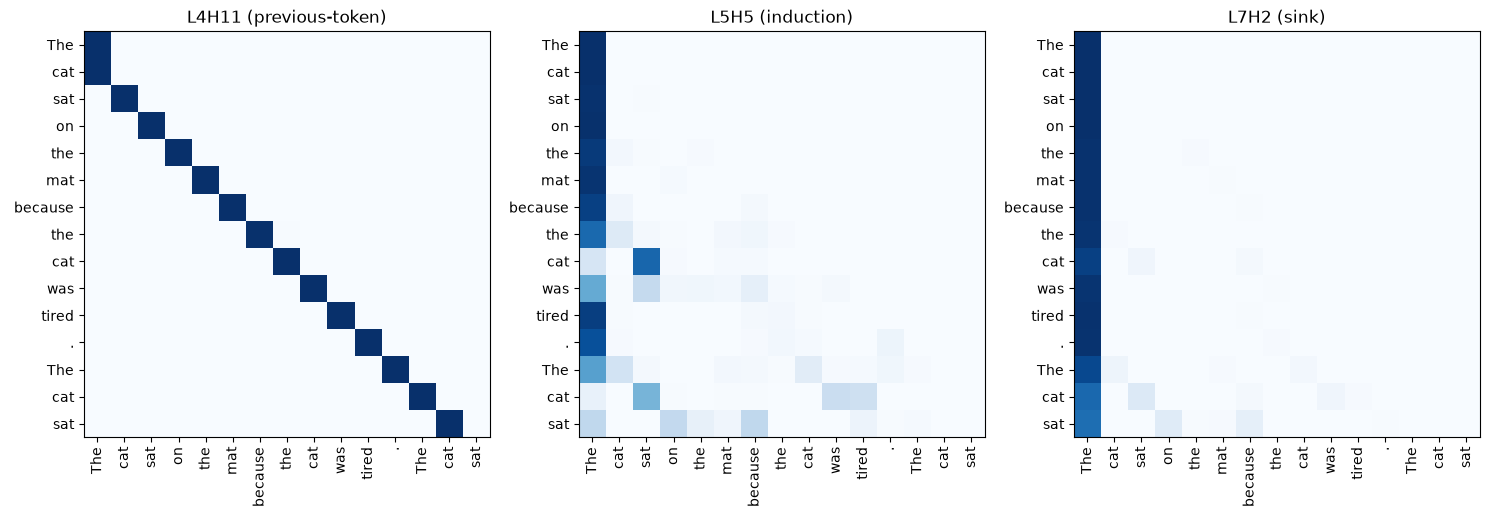

In [14]:
sent = "The cat sat on the mat because the cat was tired. The cat sat"
ids_s = tok(sent, return_tensors="pt").input_ids
with torch.no_grad(): As = gm(ids_s, output_attentions=True).attentions
toks = [tok.decode([i]) for i in ids_s[0]]
pl, ph = divmod(int(prev.argmax()), 12); il, ih = divmod(int(ind.argmax()), 12); sl, sh = divmod(int(first[1:].argmax()), 12); sl += 1
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (l_, h_, nm) in zip(ax, ((pl, ph, "previous-token"), (il, ih, "induction"), (sl, sh, "sink"))):
    a.imshow(As[l_][0, h_], cmap="Blues", vmin=0, vmax=1); a.set_title(f"L{l_}H{h_} ({nm})")
    a.set_xticks(range(len(toks))); a.set_xticklabels(toks, rotation=90); a.set_yticks(range(len(toks))); a.set_yticklabels(toks)
plt.tight_layout(); plt.show()

## 7. Training tiny attention models
Next-character prediction on TinyShakespeare with the `AttnLM` of section 0: token + learned position embedding, `L` attention layers with residuals, no MLP, no normalisation. Same 90/10 split as Module 3. Scored at positions >= 8 of non-overlapping 64-character windows, so every prediction sees at least 8 characters (the Module 3 neural LM with an 8-character window had held-out loss 1.81, the bigram 2.49). About 5 minutes in total.

In [15]:
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; V = len(chars)
ids = np.array([stoi[c] for c in text]); cut = int(0.9 * len(ids)); tr, te = ids[:cut], ids[cut:]
models = {}
for name, h, L in (("1 layer, 1 head", 1, 1), ("1 layer, 4 heads", 4, 1), ("2 layers, 4 heads", 4, 2)):
    torch.manual_seed(0); m = AttnLM(V, 64, 64, h, L); t0 = time.time(); train_attn(m, tr, steps=4000); models[name] = m
    print(f"{name:18s} params {sum(p.numel() for p in m.parameters()):6,}  train {eval_attn(m, tr[:len(te)]):.3f}  held-out {eval_attn(m, te):.3f}   ({time.time()-t0:.0f}s)")

1 layer, 1 head    params 29,121  train 2.091  held-out 2.179   (56s)


1 layer, 4 heads   params 29,121  train 1.882  held-out 2.019   (86s)


2 layers, 4 heads  params 45,761  train 1.697  held-out 1.859   (158s)


In [16]:
print(sample_attn(models["2 layers, 4 heads"], chars, stoi, "\n", 300, seed=1))



Carest Werents uusil, that me, by my shals with and from cauch
Than infil. O, and wing, here?

GLOUCESTER:
My wouldss hoth timberess?
You at Ervoles, he is put--

NoCUTIO:
Even it eldier, let, it rect-me notless!
And forth tereit,
Fixh hip
wead she mide, thear not, I'll Cluins;
For Of mingre, their


What did the heads of the one-layer model learn? Average attention by distance, over 200 held-out windows (queries at position >= 16).

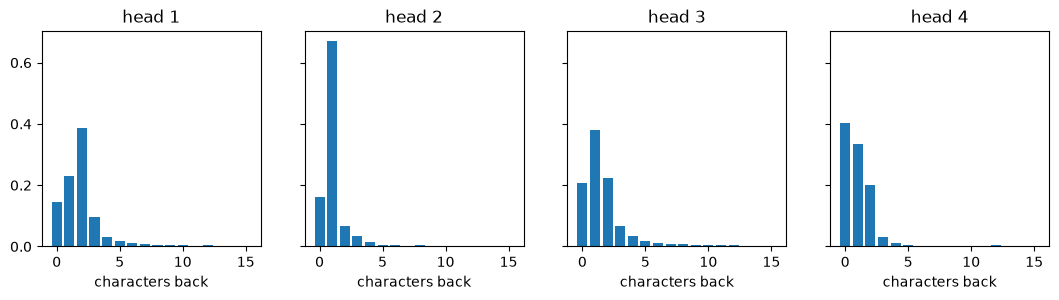

In [17]:
m1 = models["1 layer, 4 heads"]
xs = torch.as_tensor(te[: 200 * 64], dtype=torch.long).view(200, 64)
with torch.no_grad(): _, wl = m1(xs, True)
W1 = wl[0]; q_idx = torch.arange(16, 64)
prof = torch.stack([torch.stack([W1[:, hh, q_idx, q_idx - dd].mean() for dd in range(16)]) for hh in range(4)])
fig, ax = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for hh in range(4): ax[hh].bar(range(16), prof[hh]); ax[hh].set_title(f"head {hh+1}"); ax[hh].set_xlabel("characters back")
plt.show()

## Exercises
1. **Temperature of attention.** In section 2, multiply the scores by 5 or divide them by 5 before the softmax. What happens to the rows of the weight matrix? Which limit gives "copy the best match" and which gives "plain average"?
2. **No mask.** Train `AttnLM` with `causal=False` in `attention`. Why does the training loss become suspiciously low, and why is the held-out loss then terrible (or nonsense)?
3. **No position embedding.** Remove `self.pos` from `AttnLM` and retrain the 1-layer, 4-head model. Compare with the table of section 7. Why does the model still do better than a bigram?
4. **Value vs. weight.** In GPT-2, take the sink head found in section 6 and compute the norm of the value vectors `v_j` for position 0 versus other positions. Is the "sink" token's value small? (Hint: use `sp(v_)` of the same layer.)
5. **Open-ended: more heads or more layers?** Keep the parameter count of the 2-layer model roughly fixed and compare (a) 2 layers x 4 heads, (b) 1 layer x 8 heads wider, (c) 4 layers x 2 heads narrower. Plot held-out loss against steps. What would you expect to change if the data had longer-range structure?
6. **Open-ended: break an induction head.** In GPT-2, zero out the output of the best induction head (multiply its slice of the concatenated head outputs by 0 before `c_proj`) and measure the loss on the repeated-random-tokens input of section 6 for the second copy. How much does the loss on the second half increase?